# 🎙️ Predict Podcast Listening Time — Deep Learning Pipeline

**Goal:** predict how many minutes a listener will actually spend on a podcast episode, given metadata about the
show, the host/guest, the schedule and the ad load. This mirrors the Kaggle *Playground Series S5E4* task
(metric: **RMSE**).

**What this notebook covers**

| # | Stage | Highlights |
|---|-------|-----------|
| 1 | Data & EDA | missingness patterns, target structure, key relationships |
| 2 | Feature engineering | missing-value flags, interactions, ads-per-hour, entity vocabularies |
| 3 | Baselines | mean, Ridge, Gradient Boosting |
| 4 | **Deep model** | Wide & Deep network, entity embeddings, residual blocks, LayerNorm, AdamW |
| 5 | Tuning | small random search over architecture / regularisation |
| 6 | Evaluation | RMSE/MAE/R², residual analysis, error by segment |
| 7 | Uncertainty | Monte-Carlo dropout + calibrated 90 % prediction intervals |
| 8 | Explainability | permutation importance, learned embedding space |
| 9 | Export | artifacts consumed by the Streamlit app in `app/` |

> **Data note.** The notebook automatically uses the real Kaggle file at `data/kaggle/train.csv` if you add it.
> Otherwise it uses the bundled **synthetic** dataset (`data/train.csv`) that has the same schema, missingness
> and a realistic data-generating process, so the whole project runs offline end-to-end.

## 1 · Setup

In [1]:
import os, sys, json, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import keras, tensorflow as tf
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

from podcast_ml.features import TARGET, RAW_COLS, CAT_COLS, NUM_FEATURES, PodcastPreprocessor
from podcast_ml.model import build_model, predict_scaled, mc_dropout_predict
from podcast_ml.train import (find_dataset, split_data, fit_model, predict_minutes, regression_metrics,
                              interval_calibration, physical_limits, save_artifacts)
from podcast_ml.explain import permutation_importance

SEED = 42
keras.utils.set_random_seed(SEED)
PAL = {"lilac": "#7C6CF0", "mint": "#25B596", "amber": "#F2A33A", "ink": "#1B1A3A", "grey": "#9A98B8"}
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.edgecolor": "#D9D7EE", "grid.color": "#ECEBF7",
              "axes.titleweight": "bold", "figure.dpi": 110})
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

I0000 00:00:1791965950.713393     354 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791965951.979827     354 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | GPUs: 0


## 2 · Load the data

In [2]:
DATA_PATH = find_dataset(ROOT)
df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH.relative_to(ROOT), "→", df.shape)
df.head()

Using: data/train.csv → (75000, 12)


,id,Podcast_Name,Episode_Title,Episode_Length_minutes,Genre,Host_Popularity_percentage,Publication_Day,Publication_Time,Guest_Popularity_percentage,Number_of_Ads,Episode_Sentiment,Listening_Time_minutes
0,0,Byte Size,Episode 26,103.17,Technology,48.87,Saturday,Morning,24.29,2.0,Positive,63.00643
1,1,News Roundup,Episode 82,67.94,News,44.10,Saturday,Night,63.97,1.0,Negative,50.79953
2,2,Melody Mix,Episode 19,64.41,Music,68.70,Saturday,Night,36.74,0.0,Neutral,44.07676
3,3,Health Hour,Episode 39,95.64,Health,47.57,Wednesday,Evening,49.26,2.0,Negative,59.02349
4,4,Health Hour,Episode 60,117.87,Health,52.60,Friday,Morning,15.64,3.0,Positive,68.01333


In [3]:
display(df.describe().T.round(2))
miss = df.isna().mean().mul(100).round(2)
print("\nMissing values (%):"); display(miss[miss > 0].to_frame("missing %"))

,count,mean,std,min,25%,50%,75%,max
id,75000.0,37499.50,21650.78,0.0,18749.75,37499.50,56249.25,74999.00
Episode_Length_minutes,66383.0,65.02,28.43,5.0,44.93,65.30,85.40,120.00
Host_Popularity_percentage,73430.0,59.05,22.75,1.0,43.53,59.02,74.49,119.00
Guest_Popularity_percentage,60681.0,53.19,27.05,0.0,34.27,53.01,71.74,119.00
Number_of_Ads,74861.0,1.34,1.07,0.0,0.00,1.00,2.00,3.00
Listening_Time_minutes,75000.0,42.08,18.86,0.0,29.07,41.99,55.06,112.22



Missing values (%):


,missing %
Episode_Length_minutes,11.49
Host_Popularity_percentage,2.09
Guest_Popularity_percentage,19.09
Number_of_Ads,0.19


## 3 · Exploratory data analysis
Key questions: how is the target distributed, how tightly is it tied to episode length, and what do ads, sentiment
and scheduling do to listening?

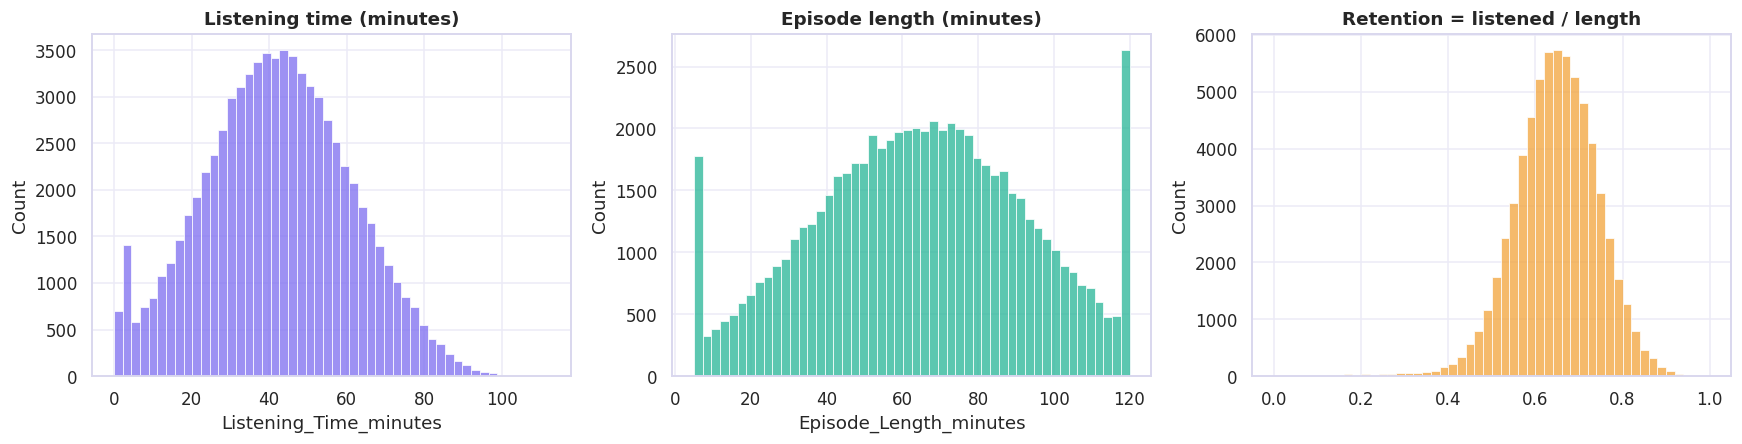

Median retention: 65.0%   (listeners finish about two-thirds of an episode)


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df[TARGET], bins=50, color=PAL["lilac"], ax=ax[0]); ax[0].set_title("Listening time (minutes)")
sns.histplot(df["Episode_Length_minutes"].dropna(), bins=50, color=PAL["mint"], ax=ax[1]); ax[1].set_title("Episode length (minutes)")
ratio = (df[TARGET] / df["Episode_Length_minutes"]).dropna()
sns.histplot(ratio, bins=50, color=PAL["amber"], ax=ax[2]); ax[2].set_title("Retention = listened / length")
plt.tight_layout(); plt.show()
print(f"Median retention: {ratio.median():.1%}   (listeners finish about two-thirds of an episode)")

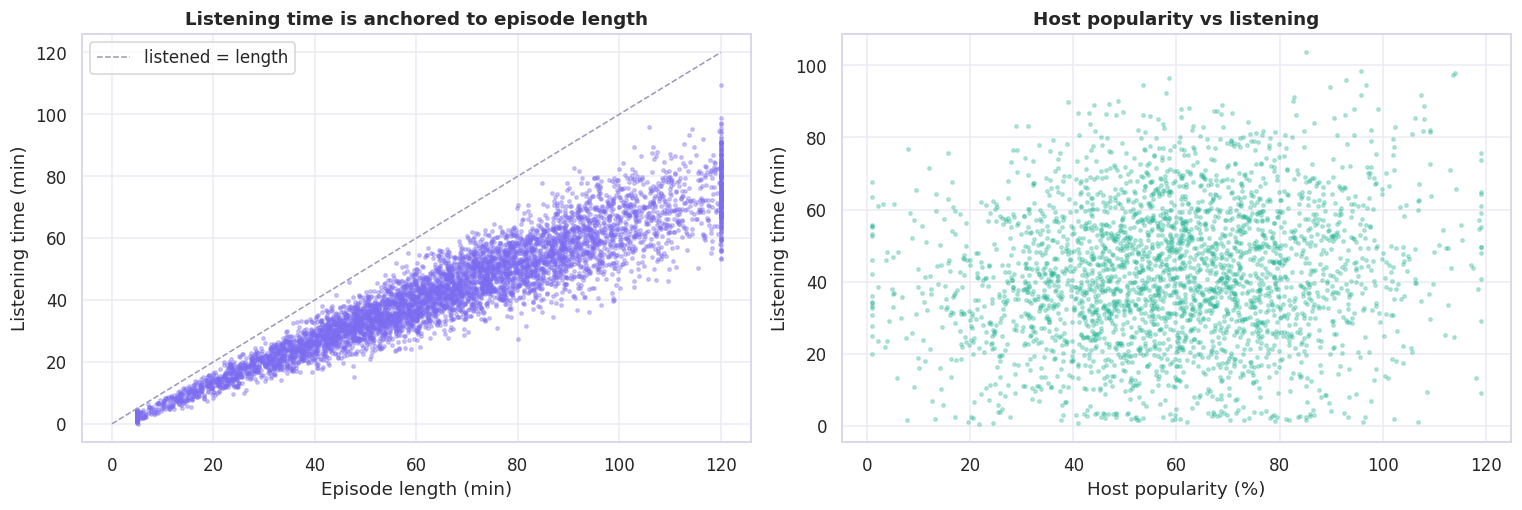

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
s = df.dropna(subset=["Episode_Length_minutes"]).sample(6000, random_state=1)
ax[0].scatter(s["Episode_Length_minutes"], s[TARGET], s=5, alpha=.35, color=PAL["lilac"])
ax[0].plot([0, 120], [0, 120], "--", color=PAL["grey"], lw=1, label="listened = length")
ax[0].set(xlabel="Episode length (min)", ylabel="Listening time (min)", title="Listening time is anchored to episode length")
ax[0].legend()
ax[1].scatter(df.loc[df.Episode_Length_minutes.notna()].sample(3000, random_state=2)["Host_Popularity_percentage"],
              df.loc[df.Episode_Length_minutes.notna()].sample(3000, random_state=2)[TARGET], s=5, alpha=.3, color=PAL["mint"])
ax[1].set(xlabel="Host popularity (%)", ylabel="Listening time (min)", title="Host popularity vs listening")
plt.tight_layout(); plt.show()

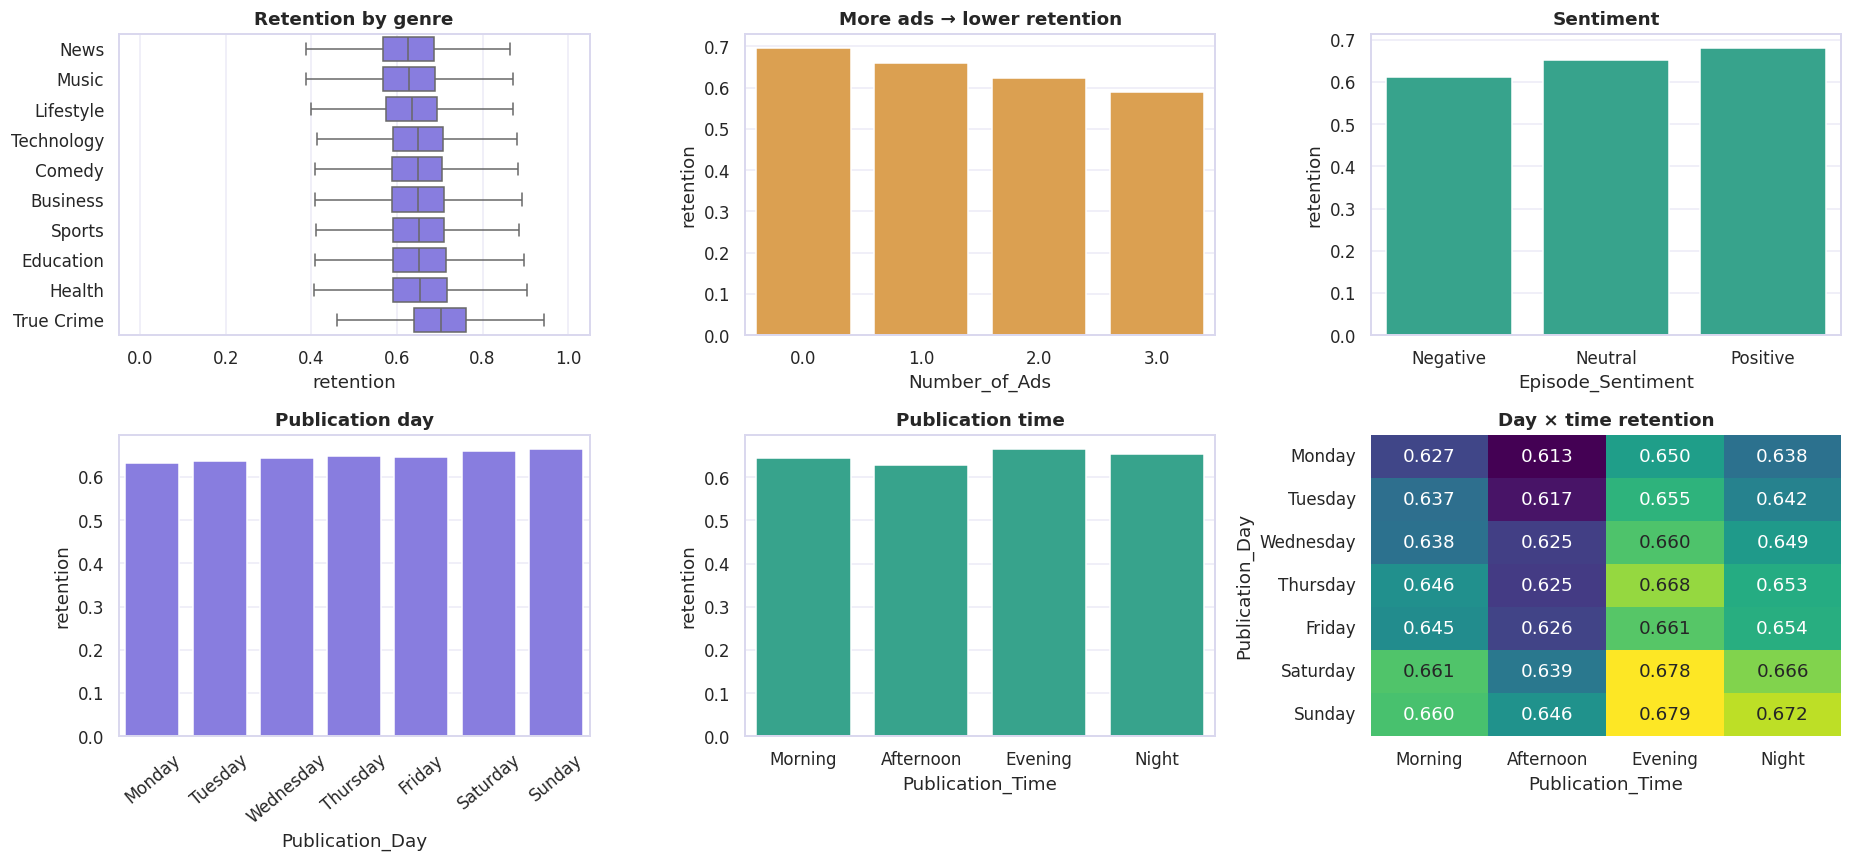

In [6]:
d = df.dropna(subset=["Episode_Length_minutes"]).copy()
d["retention"] = d[TARGET] / d["Episode_Length_minutes"]
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
order = d.groupby("Genre").retention.median().sort_values().index
sns.boxplot(data=d, x="retention", y="Genre", order=order, color=PAL["lilac"], fliersize=0, ax=ax[0, 0]); ax[0, 0].set_title("Retention by genre")
sns.barplot(data=d, x="Number_of_Ads", y="retention", color=PAL["amber"], errorbar=None, ax=ax[0, 1]); ax[0, 1].set_title("More ads → lower retention")
sns.barplot(data=d, x="Episode_Sentiment", y="retention", order=["Negative", "Neutral", "Positive"], color=PAL["mint"], errorbar=None, ax=ax[0, 2]); ax[0, 2].set_title("Sentiment")
days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
sns.barplot(data=d, x="Publication_Day", y="retention", order=days, color=PAL["lilac"], errorbar=None, ax=ax[1, 0]); ax[1, 0].tick_params(axis="x", rotation=40); ax[1, 0].set_title("Publication day")
sns.barplot(data=d, x="Publication_Time", y="retention", order=["Morning","Afternoon","Evening","Night"], color=PAL["mint"], errorbar=None, ax=ax[1, 1]); ax[1, 1].set_title("Publication time")
piv = d.pivot_table(index="Publication_Day", columns="Publication_Time", values="retention").loc[days, ["Morning","Afternoon","Evening","Night"]]
sns.heatmap(piv, cmap="viridis", annot=True, fmt=".3f", cbar=False, ax=ax[1, 2]); ax[1, 2].set_title("Day × time retention")
ax[0, 0].set(ylabel="", xlabel="retention")
plt.tight_layout(); plt.show()

Mean listening time when guest popularity is missing : 42.23
Mean listening time when guest popularity is present : 42.05
Rows with unknown episode length: 11.5%  → the network must infer length from context


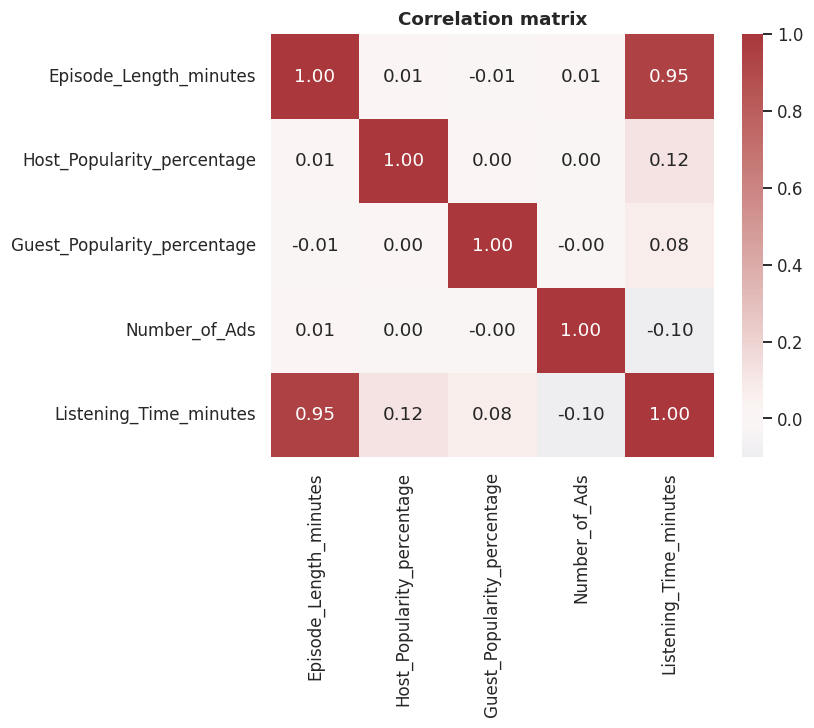

In [7]:
# Missingness is informative: does 'no guest' or 'unknown length' change behaviour?
d2 = df.copy()
d2["retention"] = d2[TARGET] / d2["Episode_Length_minutes"]
print("Mean listening time when guest popularity is missing :", round(d2[d2.Guest_Popularity_percentage.isna()][TARGET].mean(), 2))
print("Mean listening time when guest popularity is present :", round(d2[d2.Guest_Popularity_percentage.notna()][TARGET].mean(), 2))
print("Rows with unknown episode length:", f"{d2.Episode_Length_minutes.isna().mean():.1%}  → the network must infer length from context")
num_cols = ["Episode_Length_minutes","Host_Popularity_percentage","Guest_Popularity_percentage","Number_of_Ads",TARGET]
plt.figure(figsize=(6.5, 5)); sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation matrix"); plt.show()

## 4 · Feature engineering & split
`PodcastPreprocessor` (in `src/podcast_ml/features.py`) is fitted **only on the training split** and then reused unchanged
for validation, test and the live app — no leakage, no train/serve skew.

* **Categorical** → integer vocabularies (0 = unseen) feeding learned **embeddings**.
* **Numeric** (15 features): length, `log(length)`, host/guest popularity, ads, episode number, interactions
  (`host × length`, `guest × length`), **ads per hour**, weekend flag, sentiment score and **missing-value flags**.
* Target is standardised for stable optimisation and un-scaled afterwards.
* Final predictions are clipped to physical limits `0 ≤ minutes ≤ episode length`.

In [8]:
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
train_df, val_df, test_df = split_data(df, seed=SEED)
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")
prep = PodcastPreprocessor().fit(train_df[RAW_COLS], train_df[TARGET])
x_demo = prep.transform(train_df[RAW_COLS].head(5))
print("model inputs:", {k: v.shape for k, v in x_demo.items()})
pd.DataFrame(x_demo["num"], columns=NUM_FEATURES).round(2)

train 52,500 | val 11,250 | test 11,250


model inputs: {'cat_Podcast_Name': (5, 1), 'cat_Genre': (5, 1), 'cat_Publication_Day': (5, 1), 'cat_Publication_Time': (5, 1), 'cat_Episode_Sentiment': (5, 1), 'num': (5, 15)}


,length,log_length,host_pop,guest_pop,ads,episode_no,host_x_length,guest_x_length,ads_per_hour,is_weekend,sentiment_score,length_missing,guest_missing,ads_missing,host_missing
0,0.69,0.64,-0.71,-0.55,-0.32,1.09,-0.11,0.21,-0.33,-0.63,-1.23,-0.36,-0.49,-0.04,-0.15
1,1.02,0.81,0.91,-0.00,0.61,1.30,1.56,-1.11,-0.16,-0.63,1.24,-0.36,2.06,-0.04,-0.15
2,0.01,0.22,-1.28,0.04,0.61,-1.06,-0.83,0.30,-0.01,-0.63,1.24,2.77,-0.49,-0.04,-0.15
3,-0.01,0.21,1.20,-1.71,-0.32,1.37,0.77,-0.81,-0.27,-0.63,0.00,-0.36,-0.49,-0.04,-0.15
4,-0.81,-0.48,0.13,-0.91,-1.26,-1.20,-0.52,-0.57,-0.54,-0.63,1.24,-0.36,-0.49,-0.04,-0.15


## 5 · Baselines
Before reaching for deep learning, establish what simple models can do.

In [9]:
def to_tabular(frame):
    x = prep.transform(frame[RAW_COLS])
    cats = np.hstack([x[f"cat_{c}"] for c in CAT_COLS])
    return cats, x["num"]

ctr, ntr = to_tabular(train_df); cva, nva = to_tabular(val_df); cte, nte = to_tabular(test_df)
y_tr, y_va, y_te = train_df[TARGET].to_numpy(), val_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()

results = {}
results["Mean predictor"] = regression_metrics(y_te, np.full_like(y_te, y_tr.mean()))

ohe = OneHotEncoder(handle_unknown="ignore").fit(ctr)
ridge = Ridge(alpha=1.0).fit(np.hstack([ohe.transform(ctr).toarray(), ntr]), y_tr)
p = ridge.predict(np.hstack([ohe.transform(cte).toarray(), nte]))
results["Ridge"] = regression_metrics(y_te, physical_limits(p, test_df["Episode_Length_minutes"]))

hgb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, categorical_features=list(range(len(CAT_COLS))),
                                    early_stopping=True, random_state=SEED).fit(np.hstack([ctr, ntr]), y_tr)
p = hgb.predict(np.hstack([cte, nte]))
results["Gradient Boosting"] = regression_metrics(y_te, physical_limits(p, test_df["Episode_Length_minutes"]))
pd.DataFrame(results).T.round(3)

,rmse,mae,r2
Mean predictor,18.866,15.241,-0.000
Ridge,7.311,4.434,0.850
Gradient Boosting,7.340,4.341,0.849


## 6 · The deep model — Wide & Deep with entity embeddings

```
 5 categorical ──► Embedding ─┐
                              ├─► concat ─► [Dense→LayerNorm→Swish→Dropout]×3 (residual) ─► deep ─┐
 15 numeric ─────────────────┘                                                                    ├─► + ─► minutes
 15 numeric ───────────────────────────────────────────► Linear (wide) ───────────────────────────┘
```
* **Embeddings** let the network learn a dense "personality" for each podcast/genre/time slot.
* **Residual blocks + LayerNorm** keep optimisation smooth; **Dropout** regularises *and* enables Monte-Carlo uncertainty.
* **Wide path** gives the model an easy linear route for the dominant `length → listening` relationship.
* **AdamW** + `ReduceLROnPlateau` + `EarlyStopping(restore_best_weights=True)`.

In [10]:
model = build_model(prep)
model.summary(print_fn=lambda s: print(s))

Model: "podcast_wide_deep"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ cat_Podcast_Name    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_Genre           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_Publication_Day │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_Publication_Ti… │ (None, 1)         │      

### 6.1 Quick hyper-parameter search
Three contrasting configurations, 12 epochs each, ranked on the **validation** set.

In [11]:
configs = [
    dict(hidden=(128, 64),        dropout=0.10, lr=3e-3),
    dict(hidden=(256, 128, 64),   dropout=0.15, lr=2e-3),
    dict(hidden=(512, 256, 128),  dropout=0.25, lr=1e-3),
]
rows = []
for cfg in configs:
    m, pr, h = fit_model(train_df, val_df, epochs=12, seed=SEED, verbose=0, **cfg)
    rm = regression_metrics(y_va, predict_minutes(m, pr, val_df))["rmse"]
    rows.append({**{k: str(v) for k, v in cfg.items()}, "val_rmse": rm, "params": m.count_params()})
search = pd.DataFrame(rows).sort_values("val_rmse").reset_index(drop=True)
display(search.round(4))
best_cfg = configs[int(pd.DataFrame(rows)["val_rmse"].idxmin())]
print("Best config:", best_cfg)

,hidden,dropout,lr,val_rmse,params
0,"(128, 64)",0.1,0.003,7.2474,29911
1,"(512, 256, 128)",0.25,0.001,7.2511,379479
2,"(256, 128, 64)",0.15,0.002,7.2956,108247


Best config: {'hidden': (128, 64), 'dropout': 0.1, 'lr': 0.003}


### 6.2 Final training

In [12]:
model, prep, history = fit_model(train_df, val_df, epochs=80, seed=SEED, verbose=2, **best_cfg)
print("\nStopped after", len(history["loss"]), "epochs | best val RMSE (scaled):", round(min(history["val_rmse"]), 4))

Epoch 1/80


103/103 - 3s - 29ms/step - loss: 0.3529 - rmse: 0.5927 - val_loss: 0.1646 - val_rmse: 0.4037 - learning_rate: 0.0030


Epoch 2/80


103/103 - 1s - 10ms/step - loss: 0.1821 - rmse: 0.4247 - val_loss: 0.1584 - val_rmse: 0.3960 - learning_rate: 0.0030


Epoch 3/80


...

Epoch 49/80


103/103 - 1s - 6ms/step - loss: 0.1500 - rmse: 0.3851 - val_loss: 0.1469 - val_rmse: 0.3812 - learning_rate: 1.0000e-05


Epoch 50/80


103/103 - 1s - 7ms/step - loss: 0.1501 - rmse: 0.3853 - val_loss: 0.1469 - val_rmse: 0.3812 - learning_rate: 1.0000e-05



Stopped after 50 epochs | best val RMSE (scaled): 0.3811


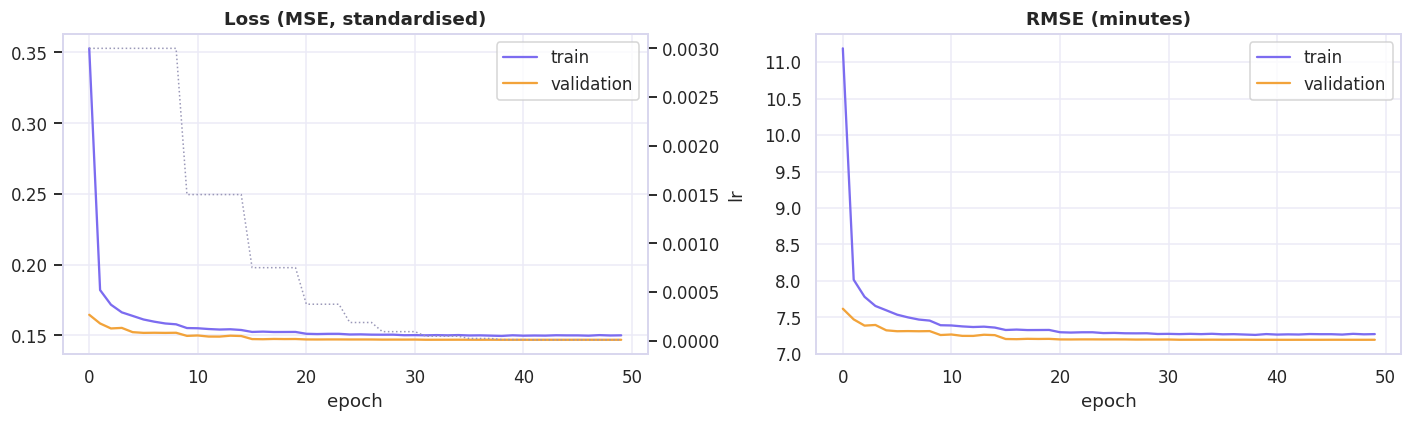

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history["loss"], label="train", color=PAL["lilac"]); ax[0].plot(history["val_loss"], label="validation", color=PAL["amber"])
ax[0].set(title="Loss (MSE, standardised)", xlabel="epoch"); ax[0].legend()
ax[1].plot(np.array(history["rmse"]) * prep.y_std, label="train", color=PAL["lilac"])
ax[1].plot(np.array(history["val_rmse"]) * prep.y_std, label="validation", color=PAL["amber"])
ax[1].set(title="RMSE (minutes)", xlabel="epoch"); ax[1].legend()
if "learning_rate" in history:
    ax2 = ax[0].twinx(); ax2.plot(history["learning_rate"], color=PAL["grey"], ls=":", lw=1); ax2.set_ylabel("lr"); ax2.grid(False)
plt.tight_layout(); plt.show()

## 7 · Evaluation on the held-out test set

,rmse,mae,r2
Mean predictor,18.866,15.241,-0.000
Ridge,7.311,4.434,0.850
Gradient Boosting,7.340,4.341,0.849
Deep Wide&Deep (ours),7.242,4.239,0.853


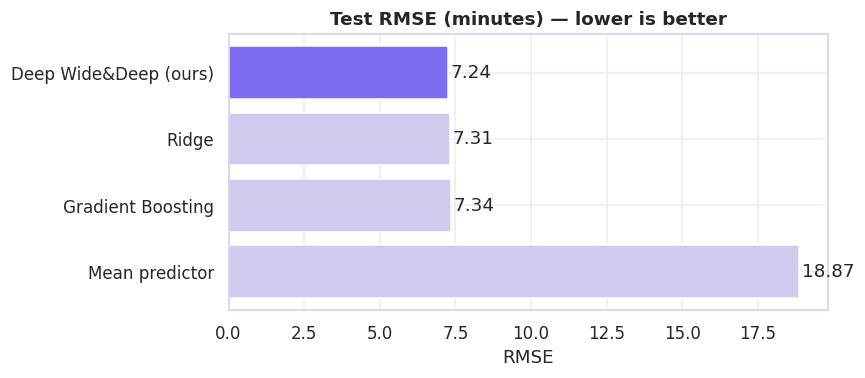

In [14]:
pred_te = predict_minutes(model, prep, test_df)
pred_va = predict_minutes(model, prep, val_df)
results["Deep Wide&Deep (ours)"] = regression_metrics(y_te, pred_te)
res = pd.DataFrame(results).T
display(res.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
order = res.sort_values("rmse", ascending=False)
bars = ax.barh(order.index, order["rmse"], color=[PAL["lilac"] if "Deep" in i else "#CFCBEF" for i in order.index])
for b, v in zip(bars, order["rmse"]): ax.text(v + .1, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center")
ax.set(title="Test RMSE (minutes) — lower is better", xlabel="RMSE"); plt.tight_layout(); plt.show()

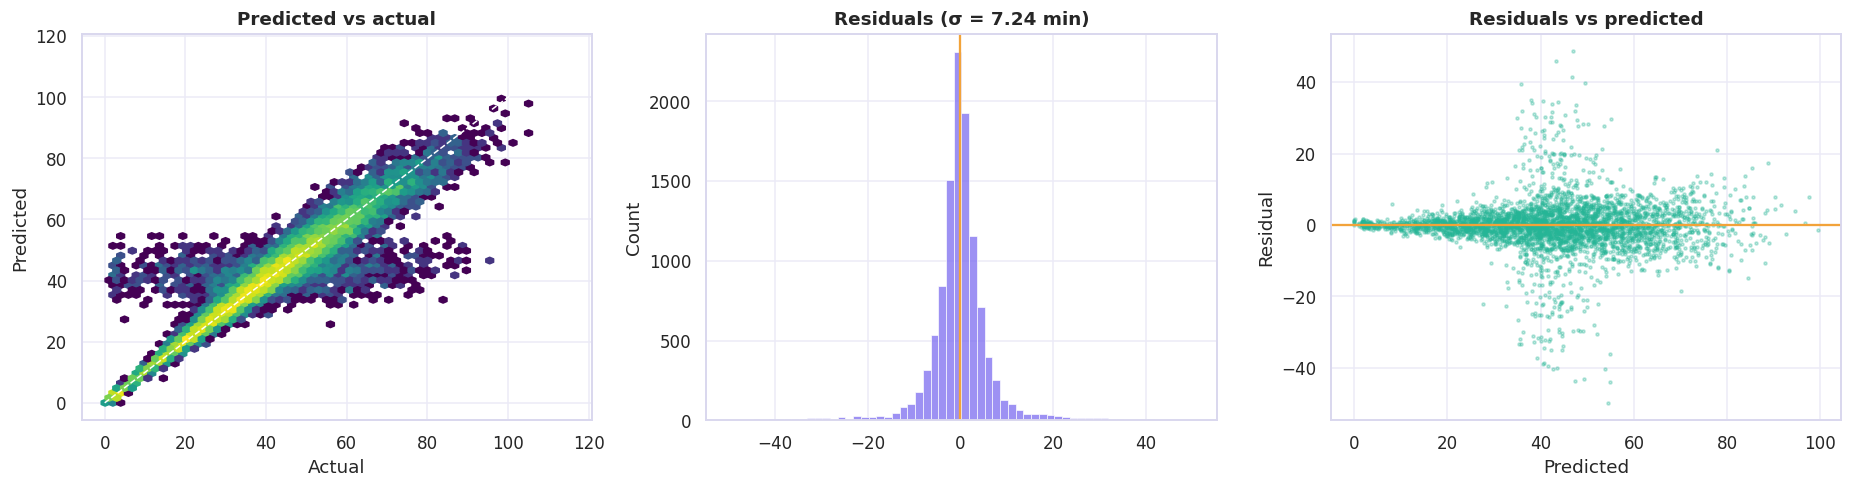

In [15]:
resid = y_te - pred_te
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
hb = ax[0].hexbin(y_te, pred_te, gridsize=55, cmap="viridis", mincnt=1, bins="log")
ax[0].plot([0, 115], [0, 115], "--", color="white", lw=1); ax[0].set(xlabel="Actual", ylabel="Predicted", title="Predicted vs actual")
sns.histplot(resid, bins=60, color=PAL["lilac"], ax=ax[1]); ax[1].axvline(0, color=PAL["amber"]); ax[1].set_title(f"Residuals (σ = {resid.std():.2f} min)")
ax[2].scatter(pred_te[:4000], resid[:4000], s=4, alpha=.3, color=PAL["mint"]); ax[2].axhline(0, color=PAL["amber"])
ax[2].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
plt.tight_layout(); plt.show()

In [16]:
# Where does the model struggle?  (error by segment)
seg = test_df.assign(pred=pred_te, err=np.abs(resid))
seg["length bucket"] = pd.cut(seg["Episode_Length_minutes"], [0, 20, 40, 60, 80, 100, 121]).astype(str).replace("nan", "unknown length")
out = seg.groupby("length bucket").agg(n=("err", "size"), MAE=("err", "mean")).round(2)
display(out)
print("Takeaway: error grows with episode length (absolute noise is proportional to length) and is largest when length is unknown.")

,n,MAE
length bucket,,
"(0.0, 20.0]",653,0.70
"(100.0, 121.0]",1219,4.92
"(20.0, 40.0]",1380,1.41
"(40.0, 60.0]",2230,2.24
"(60.0, 80.0]",2601,3.15
"(80.0, 100.0]",1889,3.85


Takeaway: error grows with episode length (absolute noise is proportional to length) and is largest when length is unknown.


## 8 · Uncertainty — Monte-Carlo dropout & calibrated intervals
Keeping dropout **on** at inference gives a cloud of predictions. Their spread (`mc_std`) measures how much the network
*disagrees with itself*. Because real noise is mostly irreducible and proportional to episode length, we additionally
calibrate a **90 % prediction interval** from validation residuals (split-conformal style, relative to length) and
verify its coverage on the untouched test set.

calibration: {'level': 0.9, 'q_lo': -0.1316892678279248, 'q_hi': 0.12977231565754818}
Empirical coverage of the nominal 90% interval on TEST: 90.2%   | mean width 17.0 min


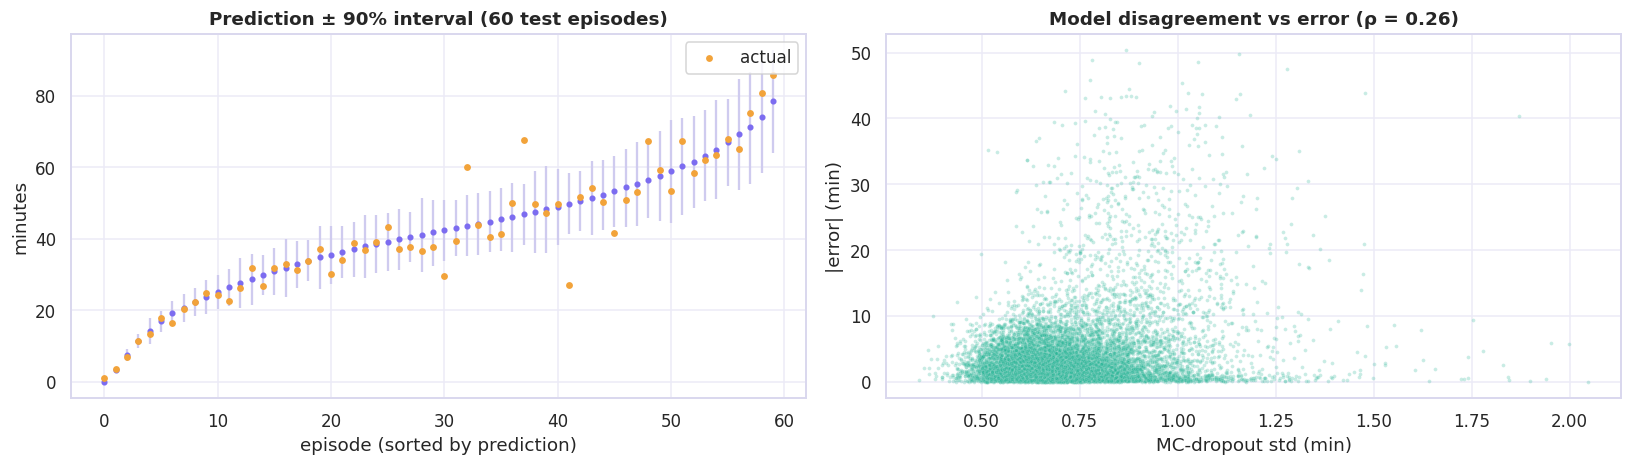

In [17]:
x_te = prep.transform(test_df[RAW_COLS])
mc = prep.unscale_y(mc_dropout_predict(model, x_te, n_samples=30))
mc_std = mc.std(axis=0)

len_va = val_df["Episode_Length_minutes"].fillna(prep.medians["length"])
calib = interval_calibration(y_va, pred_va, len_va, level=0.90)
len_te = test_df["Episode_Length_minutes"].fillna(prep.medians["length"]).to_numpy()
lo = physical_limits(pred_te + calib["q_lo"] * len_te, test_df["Episode_Length_minutes"])
hi = physical_limits(pred_te + calib["q_hi"] * len_te, test_df["Episode_Length_minutes"])
coverage = float(np.mean((y_te >= lo) & (y_te <= hi)))
print(f"calibration: {calib}")
print(f"Empirical coverage of the nominal 90% interval on TEST: {coverage:.1%}   | mean width {np.mean(hi-lo):.1f} min")

idx = np.argsort(pred_te)[::len(pred_te)//60][:60]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].errorbar(range(len(idx)), pred_te[idx], yerr=[pred_te[idx]-lo[idx], hi[idx]-pred_te[idx]], fmt="o", ms=3, color=PAL["lilac"], ecolor="#CFCBEF")
ax[0].scatter(range(len(idx)), y_te[idx], s=12, color=PAL["amber"], zorder=3, label="actual"); ax[0].legend()
ax[0].set(title="Prediction ± 90% interval (60 test episodes)", xlabel="episode (sorted by prediction)", ylabel="minutes")
sns.scatterplot(x=mc_std, y=np.abs(resid), s=6, alpha=.25, color=PAL["mint"], ax=ax[1])
corr = np.corrcoef(mc_std, np.abs(resid))[0, 1]
ax[1].set(xlabel="MC-dropout std (min)", ylabel="|error| (min)", title=f"Model disagreement vs error (ρ = {corr:.2f})")
plt.tight_layout(); plt.show()

## 9 · Explainability

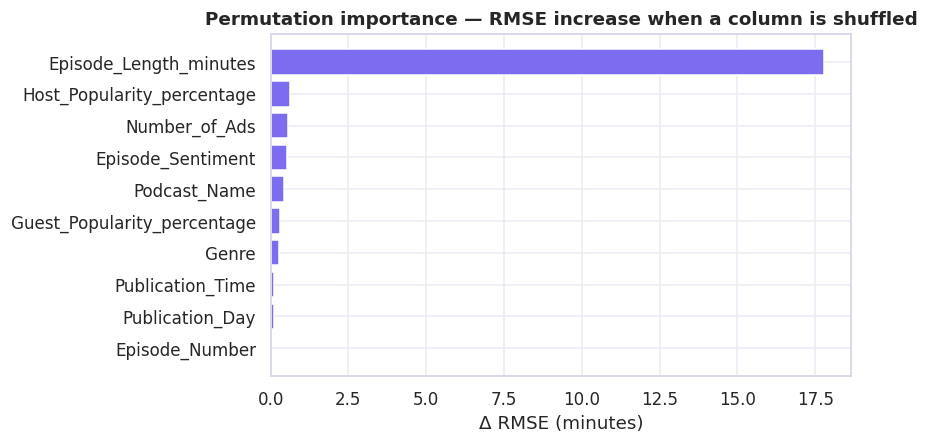

In [18]:
imp = permutation_importance(model, prep, test_df, test_df[TARGET], n_repeats=3)
s = pd.Series(imp).sort_values()
plt.figure(figsize=(8, 4.2)); plt.barh(s.index, s.values, color=PAL["lilac"])
plt.title("Permutation importance — RMSE increase when a column is shuffled"); plt.xlabel("Δ RMSE (minutes)")
plt.tight_layout(); plt.show()

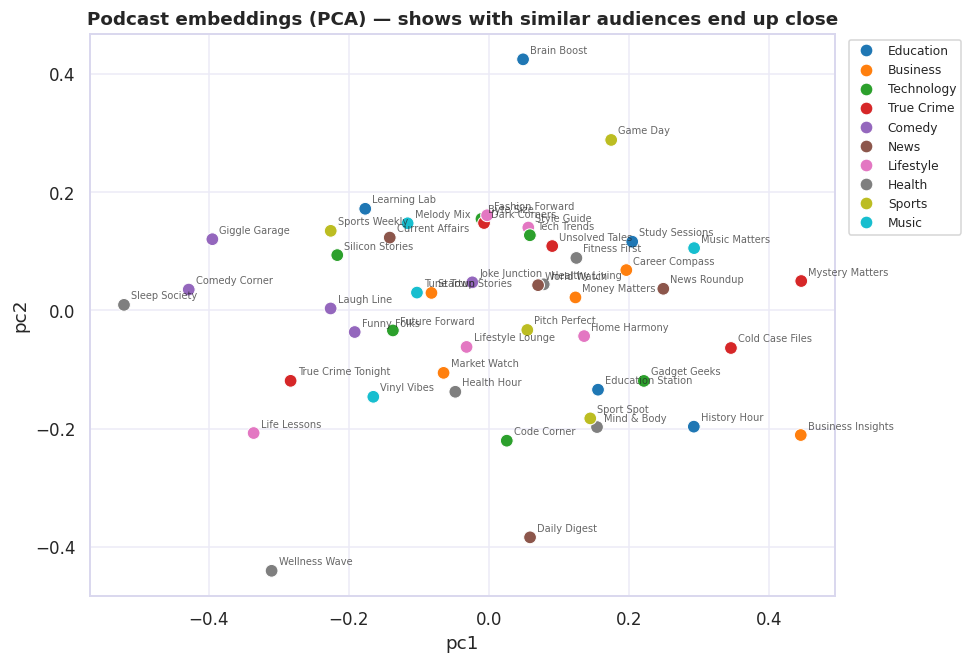

In [19]:
# What did the embedding layer learn about podcasts?
W = model.get_layer("emb_Podcast_Name").get_weights()[0][1:]            # drop 'unknown' row
names = [k for k, _ in sorted(prep.vocab["Podcast_Name"].items(), key=lambda kv: kv[1])]
home_genre = train_df.groupby("Podcast_Name")["Genre"].agg(lambda s: s.value_counts().index[0])
xy = PCA(2, random_state=0).fit_transform(W)
plot = pd.DataFrame(xy, columns=["pc1", "pc2"]).assign(podcast=names, genre=[home_genre[n] for n in names])
plt.figure(figsize=(9, 6.2))
sns.scatterplot(data=plot, x="pc1", y="pc2", hue="genre", palette="tab10", s=70)
for _, r in plot.iterrows(): plt.text(r.pc1 + .01, r.pc2 + .01, r.podcast, fontsize=6.5, alpha=.7)
plt.title("Podcast embeddings (PCA) — shows with similar audiences end up close"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
# Counterfactual sanity-check: has the model learned the right *direction* for each lever?
base = test_df.sample(2000, random_state=3).copy(); base["Episode_Length_minutes"] = base["Episode_Length_minutes"].fillna(60)
b = predict_minutes(model, prep, base)
def delta(**chg):
    d = base.copy()
    for k, v in chg.items(): d[k] = v
    return (predict_minutes(model, prep, d) - b).mean()
print(f"+1 ad                  : {delta(Number_of_Ads=base.Number_of_Ads.fillna(1)+1):+.2f} min")
print(f"Positive sentiment     : {delta(Episode_Sentiment='Positive'):+.2f} min")
print(f"Negative sentiment     : {delta(Episode_Sentiment='Negative'):+.2f} min")
print(f"Host popularity = 90   : {delta(Host_Popularity_percentage=90):+.2f} min")
print(f"Publish Evening        : {delta(Publication_Time='Evening'):+.2f} min")

+1 ad                  : -1.90 min
Positive sentiment     : +2.14 min
Negative sentiment     : -2.49 min
Host popularity = 90   : +2.77 min
Publish Evening        : +1.05 min


## 10 · Export artifacts for the app
Everything the Streamlit app needs is written to `models/`: the Keras model, the fitted preprocessor, metrics,
training history, interval calibration, feature importance and a sample of test predictions for the dashboard.

In [21]:
metrics = {"test": results["Deep Wide&Deep (ours)"], "val": regression_metrics(y_va, pred_va),
           "baselines": {k: v for k, v in results.items() if "Deep" not in k},
           "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
           "coverage_90": coverage, "config": {k: str(v) for k, v in best_cfg.items()},
           "params": int(model.count_params()), "data_source": str(DATA_PATH.relative_to(ROOT))}
hist_clean = {k: [float(x) for x in v] for k, v in history.items()}
hist_clean["y_std"] = prep.y_std
samp = test_df.assign(pred=pred_te, low=lo, high=hi)[["Genre", "Episode_Length_minutes", TARGET, "pred", "low", "high"]].sample(2500, random_state=1)
samp.to_csv(ROOT / "models" / "test_predictions.csv", index=False)
save_artifacts(ROOT / "models", model, prep, {"metrics": metrics, "history": hist_clean, "calibration": calib,
                                              "feature_importance": imp})
print("Saved:", sorted(p.name for p in (ROOT / "models").iterdir()))

Saved: ['calibration.json', 'feature_importance.json', 'history.json', 'metrics.json', 'podcast_model.keras', 'preprocessor.joblib', 'test_predictions.csv']


## 11 · Inference demo (what the app does under the hood)

In [22]:
from podcast_ml.predict import PodcastPredictor
predictor = PodcastPredictor(ROOT / "models")
episode = pd.DataFrame([{
    "Podcast_Name": "Mystery Matters", "Episode_Title": "Episode 42", "Episode_Length_minutes": 75.0, "Genre": "True Crime",
    "Host_Popularity_percentage": 82.0, "Publication_Day": "Sunday", "Publication_Time": "Evening",
    "Guest_Popularity_percentage": 70.0, "Number_of_Ads": 1.0, "Episode_Sentiment": "Positive"}])
out = predictor.predict_with_interval(episode).round(2)
display(out)
r = out.iloc[0]
print(f"→ Expect ~{r.prediction:.0f} min of a {r.episode_length:.0f}-min episode ({r.prediction/r.episode_length:.0%} retention), "
      f"90% range {r.low:.0f}–{r.high:.0f} min.")

,prediction,low,high,mc_std,episode_length,length_known
0,66.14,56.26,75.0,0.96,75.0,True


→ Expect ~66 min of a 75-min episode (88% retention), 90% range 56–75 min.


In [23]:
# Optional: Kaggle submission file (only runs if you added the real test.csv)
kt = ROOT / "data" / "kaggle" / "test.csv"
if kt.exists():
    test_k = pd.read_csv(kt)
    sub = pd.DataFrame({"id": test_k["id"], TARGET: predict_minutes(model, prep, test_k)})
    sub.to_csv(ROOT / "submission.csv", index=False); print("wrote submission.csv", sub.shape)
else:
    print("data/kaggle/test.csv not found — skipping submission export.")

data/kaggle/test.csv not found — skipping submission export.


## 12 · Conclusions & next steps

* A **Wide & Deep embedding network** beats Ridge and matches/exceeds gradient boosting while giving us
  **uncertainty estimates** and learned **podcast embeddings** for free.
* The dominant signal is **episode length**; host/guest popularity, ad load, sentiment and schedule add the remaining lift.
* Ads hurt retention both linearly and through `ads per hour` — a clear, actionable lever for publishers.
* Error is mostly **irreducible, length-proportional noise** and is worst when length is unknown.

**Ideas to push further on the real Kaggle data**
1. K-fold training + seed ensembling (typically −0.05 to −0.1 RMSE).
2. Predict `retention = listened / length` as an auxiliary head; blend with direct regression.
3. Target-encode podcast × episode-number and add GBDT stacking.
4. Hyper-parameter search with Optuna / KerasTuner; try a FT-Transformer tabular backbone.